# Лабораторная работа №3. Моделирование фильтров

**Вариант:** группа — 2, ПК — 4.

$N = №ПК + №группы = 4 + 2 = 6$, $M = N \bmod 10 = 6$, $L = N \bmod 3 = 0$.

| | По варианту ($L = 0$) |
|---|---|
| Сигнал | видеоимпульс длительностью $t_и = N = 6$ нс |
| Идеальный фильтр | полосовой, $f_н = 1/t_и = 166{,}7$ МГц, $f_в = 2/t_и = 333{,}3$ МГц |
| Фильтры БИХ | Баттерворта и Чебышёва II рода (пульсации вне полосы пропускания), $n = 4$ |

Параметры моделирования: $f_д = 4$ ГГц ($\Delta t = 0{,}25$ нс, импульс — 24 отсчёта; $f_д/2 = 2$ ГГц ≫ $f_в$), длительность интервала 1000 нс ($\Delta f = 1$ МГц).

Порядок БИХ-фильтров в задании не указан, поэтому взят $n = 4$ (порядок НЧ-прототипа; полосовые фильтры получаются 8-го порядка). Для фильтра Чебышёва II ослабление в полосе задерживания — 40 дБ. У Чебышёва II частоты в `cheby2` задают границы полосы задерживания, поэтому они взяты в 1,4 раза шире ($f_н/1{,}4$ и $1{,}4f_в$). Тогда на частотах $f_н$, $f_в$ ослабление составляет около 3 дБ, и фильтры сравниваются при одинаковой полосе пропускания.

In [1]:
%matplotlib inline
import numpy as np
import math
from numpy.fft import fft, ifft, rfft, fftfreq, fftshift
from scipy import signal as dsp
import matplotlib.pyplot as plt
from toolbox import generate_single_chip
from scheme import draw_scheme

plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 110,
                     'axes.grid': True, 'grid.alpha': 0.3})

N = 4 + 2                   # №ПК + №группы
M = N % 10
L = N % 3
print(f'N = {N}, M = {M}, L = {L}')

N = 6, M = 6, L = 0


## 1. Растекание спектра (демонстрация из шаблона)

Сигнал из конечного числа отсчётов при ДПФ считается периодическим. Если в интервал не укладывается целое число периодов синусоиды, на границе периодов возникает разрыв фазы, и энергия «растекается» по соседним частотным отсчётам. Окно Хэмминга сглаживает края и уменьшает растекание.

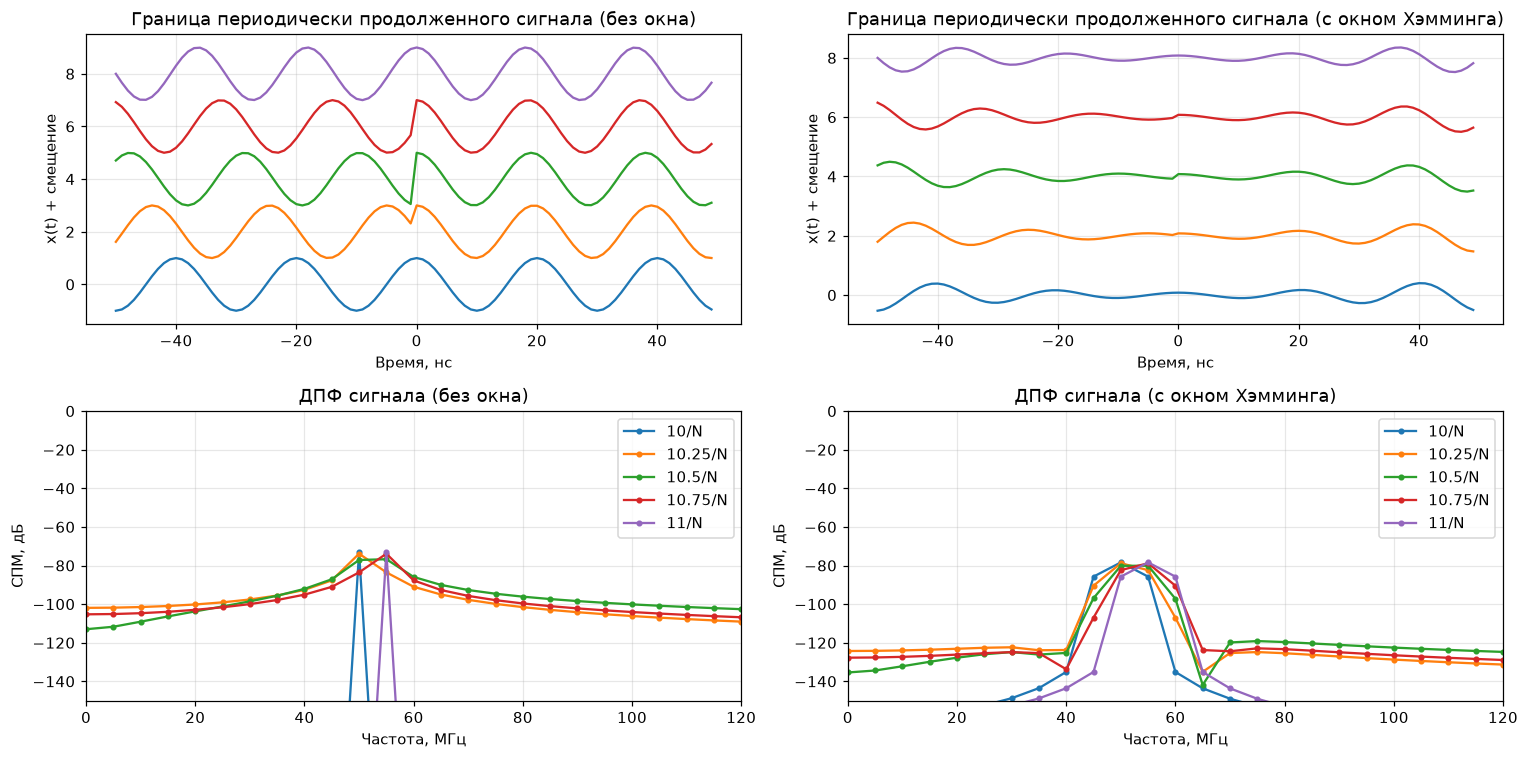

In [2]:
f_d = 1e9
t_d = 1 / f_d
n_samples = 200
t_ax = np.arange(n_samples) * t_d
f_ax = np.fft.rfftfreq(n_samples, t_d)
ks = [10, 10.25, 10.5, 10.75, 11]          # частота в отсчётах ДПФ
n2W = f_d * n_samples

fig, axs = plt.subplots(2, 2, figsize=(14, 7))
for use_window, col in [(False, 0), (True, 1)]:
    for i, k in enumerate(ks):
        x = np.cos(2 * np.pi * f_d / n_samples * k * t_ax)
        if use_window:
            x = x * np.hamming(n_samples)
        X = np.abs(rfft(x))**2 / n2W
        axs[0, col].plot((t_ax - t_ax[50])[:100] * 1e9, np.roll(x, 50)[:100] + 2 * i, label=f'{k}/N')
        axs[1, col].plot(f_ax / 1e6, 10 * np.log10(X + 1e-30), '.-', label=f'{k}/N')
    w = 'с окном Хэмминга' if use_window else 'без окна'
    axs[0, col].set(title=f'Граница периодически продолженного сигнала ({w})', xlabel='Время, нс', ylabel='x(t) + смещение')
    axs[1, col].set(title=f'ДПФ сигнала ({w})', xlabel='Частота, МГц', ylabel='СПМ, дБ', xlim=(0, 120), ylim=(-150, 0))
    axs[1, col].legend()
plt.tight_layout()

## 2. Формирование сигнала по варианту: видеоимпульс $t_и = 6$ нс

Спектр прямоугольного видеоимпульса:
$$S(f) = A\,t_и\,\frac{\sin(\pi f t_и)}{\pi f t_и}\,e^{-j\pi f t_и}.$$
Нули спектра расположены на частотах $k/t_и$: 166,7; 333,3; 500 МГц… Поэтому полосовой фильтр $[1/t_и;\ 2/t_и]$ выделяет **первый боковой лепесток** спектра.

Отсчётов: 4000, отсчётов в импульсе: 24, fн = 166.7 МГц, fв = 333.3 МГц


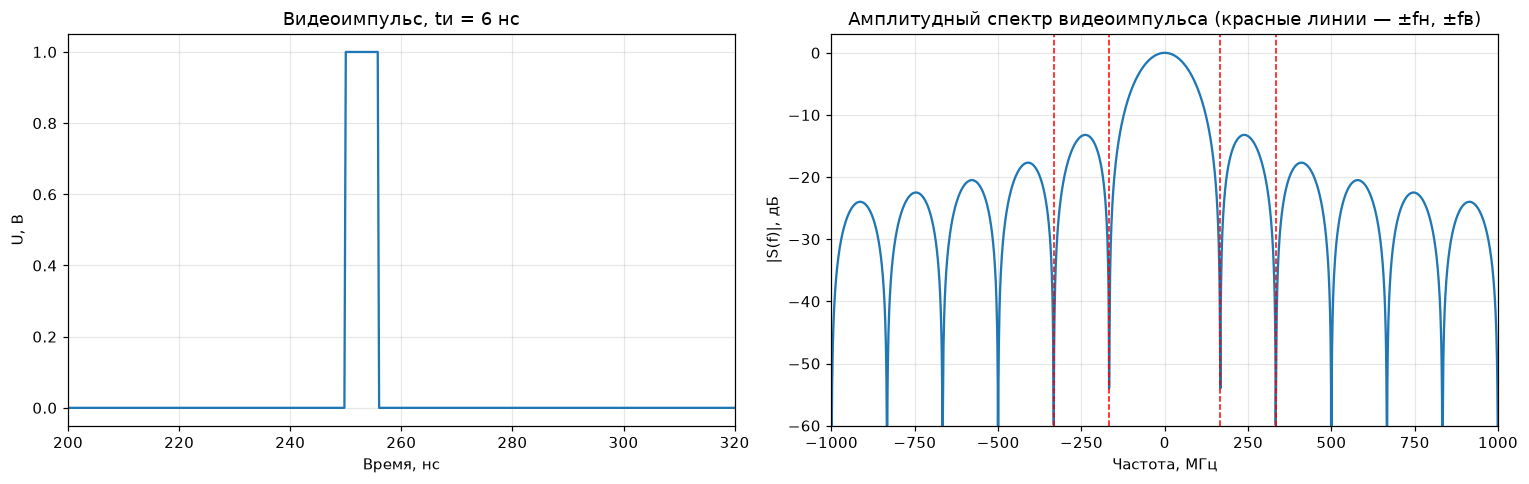

In [3]:
f_d = 4e9               # частота дискретизации, Гц
t_d = 1 / f_d
t_win = 1000e-9         # длительность интервала, с
t_imp = N * 1e-9        # длительность импульса, с
f_low, f_high = 1 / t_imp, 2 / t_imp     # частоты среза полосового фильтра

n_samples = int(round(t_win / t_d))
# +t_d/2 защищает от округления вниз в math.floor внутри toolbox (1000e-9/0.25e-9 = 3999.999...)
s_v = np.array(generate_single_chip('video', t_d, t_win + t_d/2, t_imp + t_d/2), dtype=float)
n_shift = n_samples // 4
signal = np.roll(s_v, n_shift)           # импульс начинается в момент t = 250 нс

t_ax = np.arange(n_samples) * t_d
f_ax_2 = fftshift(fftfreq(n_samples, t_d))
spec = fftshift(fft(signal)) * t_d       # спектральная плотность, В·с
print(f'Отсчётов: {n_samples}, отсчётов в импульсе: {int(signal.sum())}, '
      f'fн = {f_low/1e6:.1f} МГц, fв = {f_high/1e6:.1f} МГц')

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].plot(t_ax * 1e9, signal)
axs[0].set(title=f'Видеоимпульс, tи = {N} нс', xlabel='Время, нс', ylabel='U, В', xlim=(200, 320))
axs[1].plot(f_ax_2 / 1e6, 20 * np.log10(np.abs(spec) / np.abs(spec).max() + 1e-12))
for f in (f_low, f_high):
    axs[1].axvline(f / 1e6, color='r', ls='--', lw=1)
    axs[1].axvline(-f / 1e6, color='r', ls='--', lw=1)
axs[1].set(title='Амплитудный спектр видеоимпульса (красные линии — ±fн, ±fв)',
           xlabel='Частота, МГц', ylabel='|S(f)|, дБ', xlim=(-1000, 1000), ylim=(-60, 3))
plt.tight_layout()

## 3. Идеальный полосовой фильтр

Идеальный фильтр задаётся в частотной области по сетке БПФ. Отсчёт $k$ спектра соответствует частоте $f_k = k/(N\Delta t)$ при $k < N/2$ и $f_k = (k-N)/(N\Delta t)$ для второй половины, которая отвечает отрицательным частотам. Коэффициент передачи
$$K(f) = \begin{cases}1, & f_н \le |f| \le f_в,\\ 0, & \text{иначе.}\end{cases}$$
АЧХ задаётся симметричной относительно нуля, поэтому сигнал после ОБПФ остаётся действительным, а ФЧХ равна нулю.

Импульсная характеристика идеального полосового фильтра:
$$h(t) = 2f_в\,\mathrm{sinc}(2f_в t) - 2f_н\,\mathrm{sinc}(2f_н t) = 2\Delta f\,\mathrm{sinc}(\Delta f\,t)\cos(2\pi f_0 t),$$
где $\Delta f = f_в - f_н$, $f_0 = (f_н+f_в)/2$. Она бесконечна и симметрична относительно $t = 0$, то есть $h(t)\ne0$ при $t<0$: отклик возникает **до** прихода воздействия. Значит, идеальный фильтр физически нереализуем (нарушен принцип причинности).

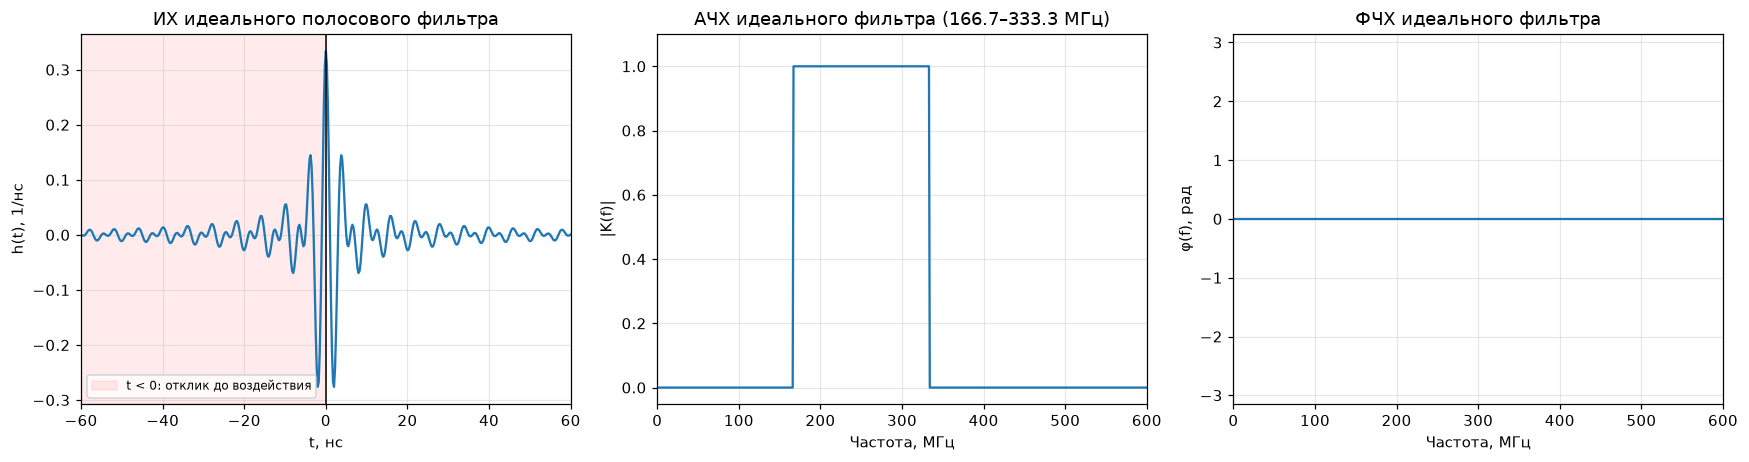

In [4]:
def ideal_filter(x, f_cut, t_d, btype='bandpass'):
    """Идеальный фильтр в частотной области: обнуление отсчётов БПФ вне полосы."""
    n = x.shape[-1]
    f = np.abs(fftfreq(n, t_d))                       # частоты отсчётов БПФ (с учётом отрицательных)
    in_band = (f >= f_cut[0]) & (f <= f_cut[1])
    K = in_band.astype(float) if btype == 'bandpass' else (~in_band).astype(float)
    y = ifft(fft(x, axis=-1) * K, axis=-1)
    if np.max(np.abs(y.imag)) > 1e-12:
        raise ValueError('Результат комплексный, хотя исходный сигнал действительный.')
    return y.real, K


signal_out_ideal, K_ideal = ideal_filter(signal, (f_low, f_high), t_d)

def delta(n, m=0):
    d = np.zeros(n)
    d[int(m)] = 1
    return d

n0 = n_samples // 2                                     # дельта-импульс в середине интервала
ir_ideal, _ = ideal_filter(delta(n_samples, n0), (f_low, f_high), t_d)
t_ir = (np.arange(n_samples) - n0) * t_d                 # время относительно момента воздействия

f_pos = fftfreq(n_samples, t_d)[:n_samples // 2]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
axs[0].plot(t_ir * 1e9, ir_ideal / t_d / 1e9)
axs[0].axvline(0, color='k', lw=1)
axs[0].axvspan(-60, 0, color='r', alpha=0.08, label='t < 0: отклик до воздействия')
axs[0].set(title='ИХ идеального полосового фильтра', xlabel='t, нс', ylabel='h(t), 1/нс', xlim=(-60, 60))
axs[0].legend(loc='lower left', fontsize=8)
axs[1].plot(f_pos / 1e6, K_ideal[:n_samples // 2])
axs[1].set(title=f'АЧХ идеального фильтра ({f_low/1e6:.1f}–{f_high/1e6:.1f} МГц)',
           xlabel='Частота, МГц', ylabel='|K(f)|', xlim=(0, 600), ylim=(-0.05, 1.1))
axs[2].plot(f_pos / 1e6, np.angle(fft(np.fft.ifftshift(ir_ideal)))[:n_samples // 2] * K_ideal[:n_samples // 2])
axs[2].set(title='ФЧХ идеального фильтра', xlabel='Частота, МГц', ylabel='φ(f), рад', xlim=(0, 600), ylim=(-np.pi, np.pi))
plt.tight_layout()

## 4. Фильтры Баттерворта и Чебышёва II рода

- **Баттерворт:** максимально плоская АЧХ, $|K(\omega)|^2 = \dfrac{1}{1+(\omega/\omega_c)^{2n}}$ для НЧ-прототипа.
- **Чебышёв II рода:** АЧХ монотонна в полосе пропускания и имеет равноволновые пульсации в полосе задерживания, $|K(\omega)|^2 = \dfrac{1}{1+\dfrac{1}{\varepsilon^2 T_n^2(\omega_s/\omega)}}$, где $T_n$ — полином Чебышёва. При том же порядке спад АЧХ у Чебышёва II круче.

Полосовые фильтры получаются из НЧ-прототипа заменой переменной, цифровые — билинейным преобразованием (`scipy.signal.butter`, `cheby2`).
Для численной устойчивости коэффициенты хранятся в виде каскада биквадратных звеньев (`output='sos'`). Фильтрация причинная (`sosfilt`): так отклик реального фильтра можно сравнить с откликом идеального.

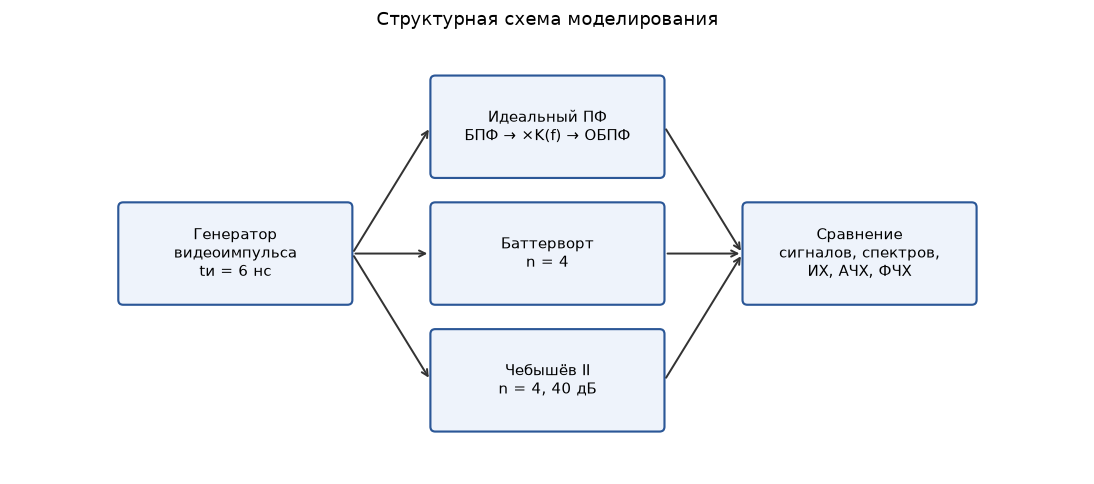

In [5]:
filt_order = 4                  # порядок НЧ-прототипа
s_band_attenuation_db = 40      # ослабление в полосе задерживания, Чебышёв II
cheb_edge_factor = 1.4          # расширение границ полосы задерживания для cheby2

sos_btr = dsp.butter(filt_order, [f_low, f_high], btype='bandpass', fs=f_d, output='sos')
sos_cheb = dsp.cheby2(filt_order, s_band_attenuation_db,
                      [f_low / cheb_edge_factor, f_high * cheb_edge_factor],
                      btype='bandpass', fs=f_d, output='sos')

signal_out_btr = dsp.sosfilt(sos_btr, signal)
signal_out_cheb = dsp.sosfilt(sos_cheb, signal)

draw_scheme(
    blocks={
        'g':  (0, 0, f'Генератор\nвидеоимпульса\ntи = {N} нс'),
        'i':  (3.2, 1.3, 'Идеальный ПФ\nБПФ → ×K(f) → ОБПФ'),
        'b':  (3.2, 0, f'Баттерворт\nn = {filt_order}'),
        'c':  (3.2, -1.3, f'Чебышёв II\nn = {filt_order}, {s_band_attenuation_db} дБ'),
        'o':  (6.4, 0, 'Сравнение\nсигналов, спектров,\nИХ, АЧХ, ФЧХ'),
    },
    arrows=[('g', 'i', ''), ('g', 'b', ''), ('g', 'c', ''), ('i', 'o', ''), ('b', 'o', ''), ('c', 'o', '')],
    title='Структурная схема моделирования', size=(11, 4.5), box_w=2.3, box_h=0.95);

### 4.1 Сигналы на входе и выходах фильтров

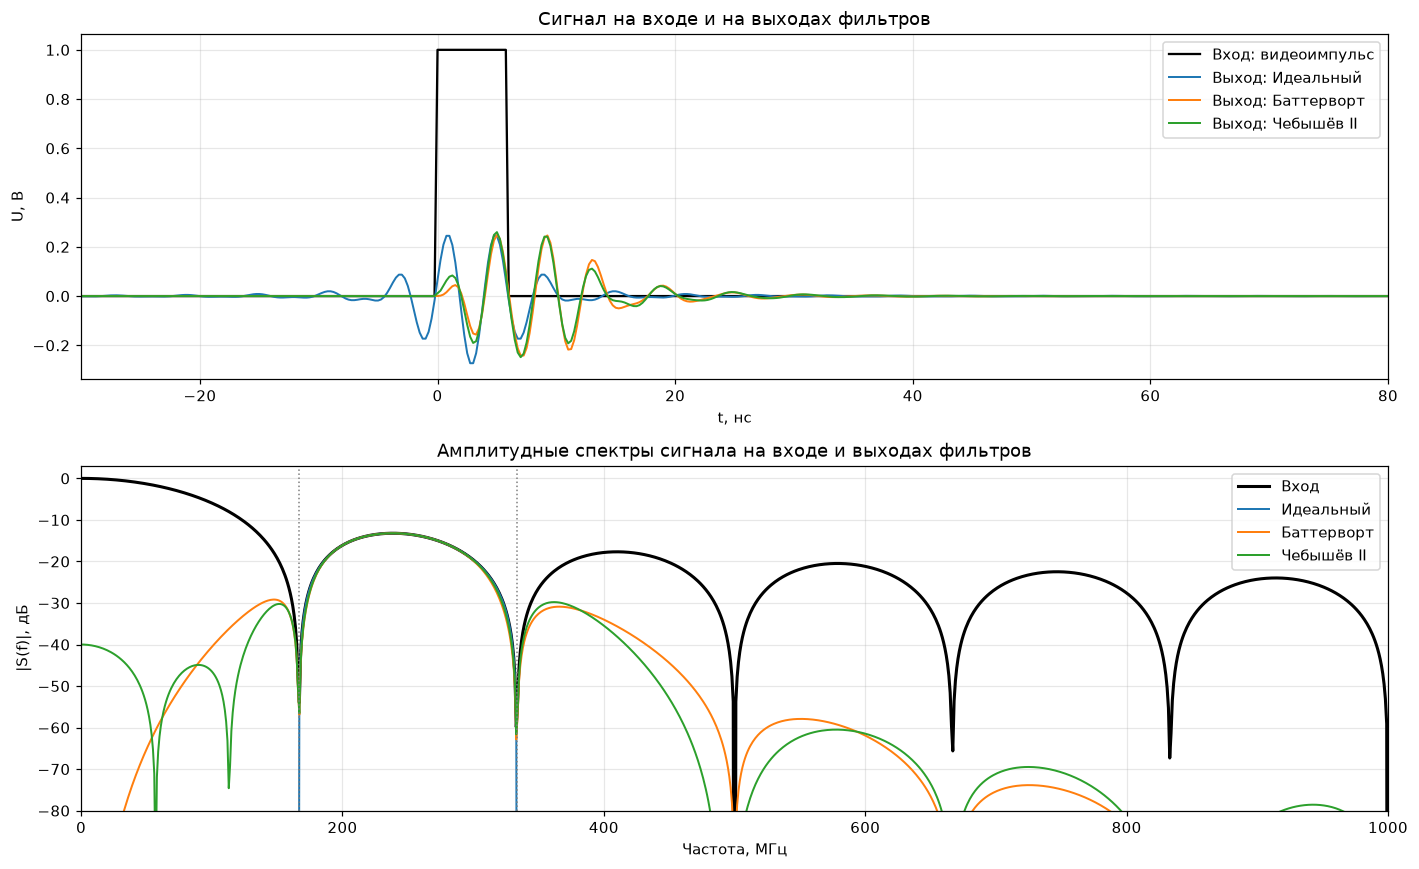

In [6]:
names = ['Идеальный', 'Баттерворт', 'Чебышёв II']
outs = [signal_out_ideal, signal_out_btr, signal_out_cheb]
t_ns = (t_ax - n_shift * t_d) * 1e9           # время относительно начала импульса

fig, axs = plt.subplots(2, 1, figsize=(13, 8))
axs[0].plot(t_ns, signal, 'k', lw=1.5, label='Вход: видеоимпульс')
for y, nm in zip(outs, names):
    axs[0].plot(t_ns, y, lw=1.3, label=f'Выход: {nm}')
axs[0].set(title='Сигнал на входе и на выходах фильтров', xlabel='t, нс', ylabel='U, В', xlim=(-30, 80))
axs[0].legend()

for y, nm in zip([signal] + outs, ['Вход'] + names):
    S = np.abs(fftshift(fft(y)) * t_d)
    axs[1].plot(f_ax_2 / 1e6, 20 * np.log10(S / np.abs(spec).max() + 1e-12), lw=1.3 if nm != 'Вход' else 2,
                color='k' if nm == 'Вход' else None, label=nm)
for f in (f_low, f_high):
    axs[1].axvline(f / 1e6, color='gray', ls=':', lw=1)
axs[1].set(title='Амплитудные спектры сигнала на входе и выходах фильтров', xlabel='Частота, МГц',
           ylabel='|S(f)|, дБ', xlim=(0, 1000), ylim=(-80, 3))
axs[1].legend()
plt.tight_layout()

### 4.2 Характеристики фильтров: ИХ, АЧХ, ФЧХ

ИХ получена как отклик на дельта-импульс в момент $t = 0$. АЧХ и ФЧХ БИХ-фильтров вычислены по коэффициентам (`sosfreqz`). У идеального фильтра они получены по его спектральной характеристике $K(f)$.

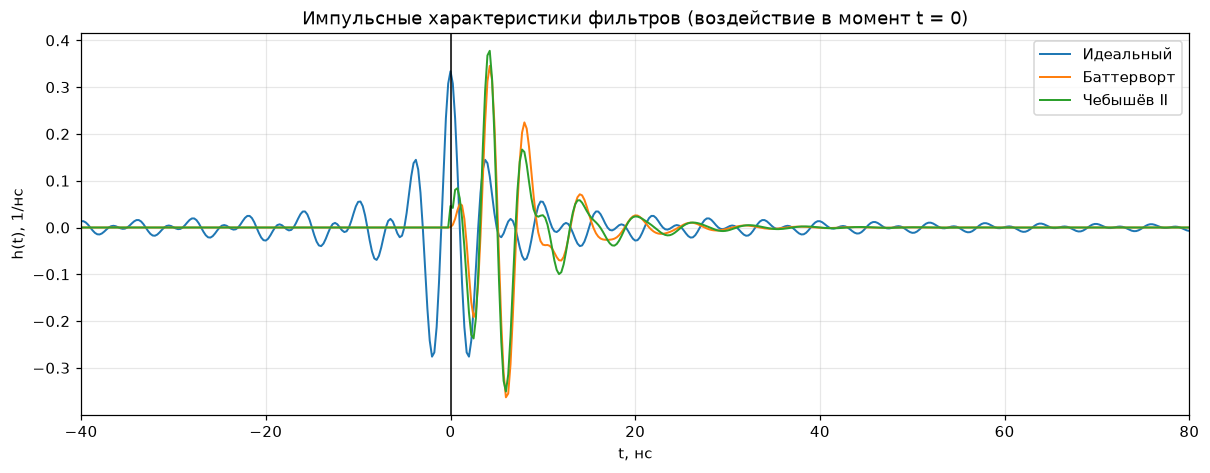

In [7]:
d = delta(n_samples, n0)
ir_btr = dsp.sosfilt(sos_btr, d)
ir_cheb = dsp.sosfilt(sos_cheb, d)

fig, ax = plt.subplots(figsize=(13, 4.5))
for ir, nm in zip([ir_ideal, ir_btr, ir_cheb], names):
    ax.plot(t_ir * 1e9, ir / t_d / 1e9, lw=1.3, label=nm)
ax.axvline(0, color='k', lw=1)
ax.set(title='Импульсные характеристики фильтров (воздействие в момент t = 0)',
       xlabel='t, нс', ylabel='h(t), 1/нс', xlim=(-40, 80))
ax.legend();

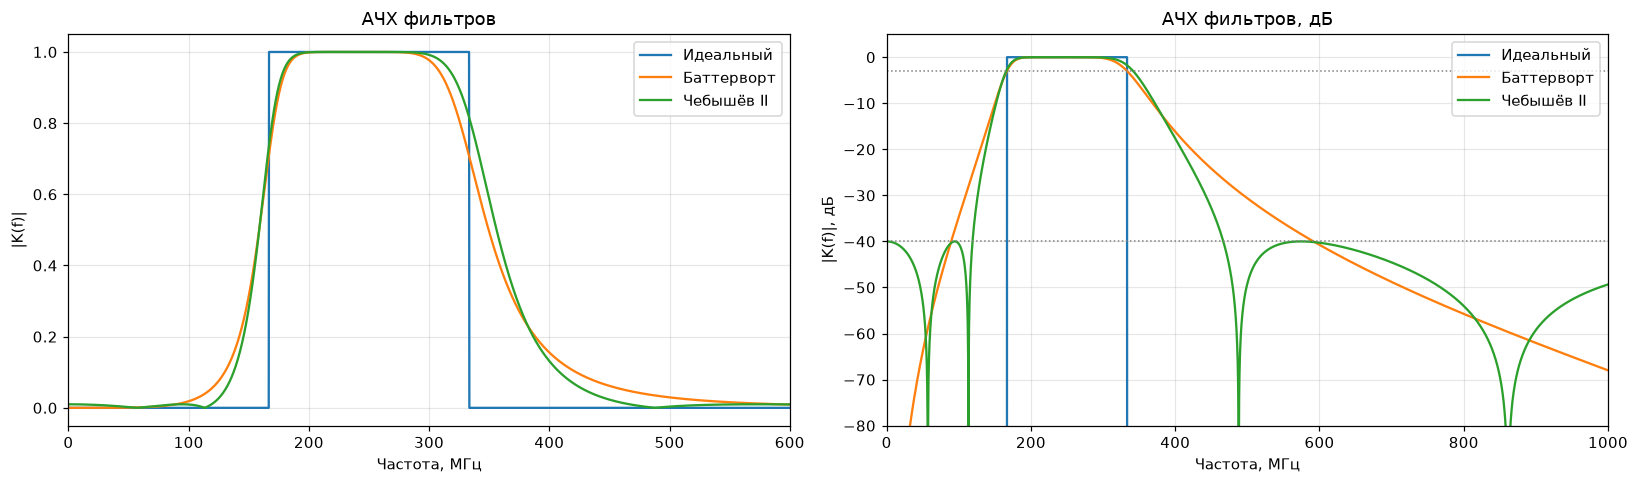

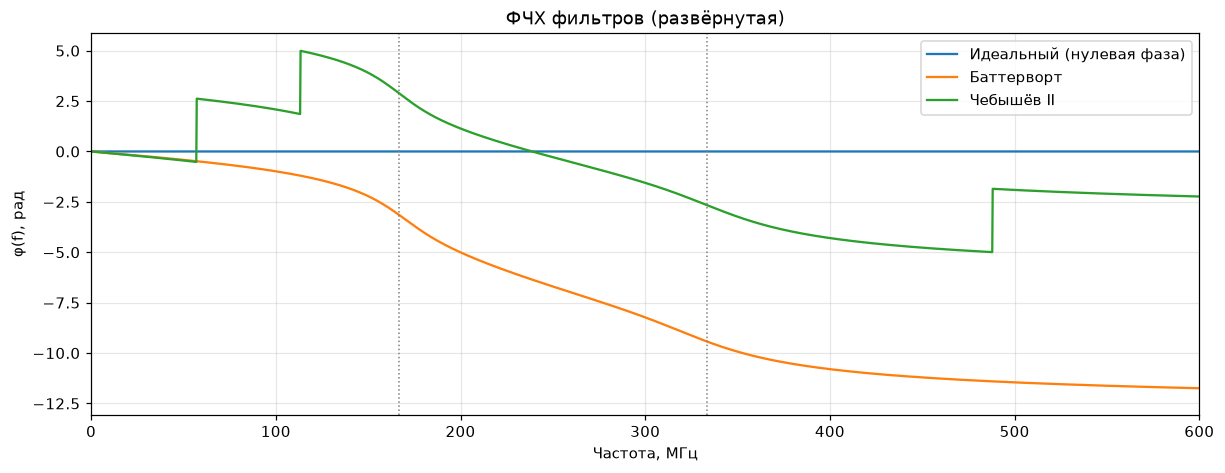

In [8]:
f_resp = np.linspace(1e6, 1000e6, 4000)
_, h_btr = dsp.sosfreqz(sos_btr, worN=f_resp, fs=f_d)
_, h_cheb = dsp.sosfreqz(sos_cheb, worN=f_resp, fs=f_d)
k_ideal = ((f_resp >= f_low) & (f_resp <= f_high)).astype(float)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for h, nm in zip([k_ideal, h_btr, h_cheb], names):
    axs[0].plot(f_resp / 1e6, np.abs(h), lw=1.5, label=nm)
    axs[1].plot(f_resp / 1e6, 20 * np.log10(np.abs(h) + 1e-12), lw=1.5, label=nm)
axs[0].set(title='АЧХ фильтров', xlabel='Частота, МГц', ylabel='|K(f)|', xlim=(0, 600))
axs[1].set(title='АЧХ фильтров, дБ', xlabel='Частота, МГц', ylabel='|K(f)|, дБ', xlim=(0, 1000), ylim=(-80, 5))
axs[1].axhline(-3, color='gray', ls=':', lw=1)
axs[1].axhline(-s_band_attenuation_db, color='gray', ls=':', lw=1)
for ax in axs:
    ax.legend()
plt.tight_layout()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(f_resp / 1e6, np.zeros_like(f_resp), lw=1.5, label='Идеальный (нулевая фаза)')
ax.plot(f_resp / 1e6, np.unwrap(np.angle(h_btr)), lw=1.5, label='Баттерворт')
ax.plot(f_resp / 1e6, np.unwrap(np.angle(h_cheb)), lw=1.5, label='Чебышёв II')
for f in (f_low, f_high):
    ax.axvline(f / 1e6, color='gray', ls=':', lw=1)
ax.set(title='ФЧХ фильтров (развёрнутая)', xlabel='Частота, МГц', ylabel='φ(f), рад', xlim=(0, 600))
ax.legend();

## Выводы

1. Сформирован видеоимпульс длительностью 6 нс. Его амплитудный спектр имеет вид $|\mathrm{sinc}(\pi f t_и)|$ с нулями на частотах $k/t_и$. Полоса $[166{,}7;\ 333{,}3]$ МГц совпадает с первым боковым лепестком спектра.
2. **Идеальный фильтр** реализован обнулением отсчётов БПФ вне полосы $f_н \le |f| \le f_в$, отдельно для положительных и отрицательных частот. Благодаря этой симметрии выходной сигнал действительный. АЧХ прямоугольная, ФЧХ нулевая. ИХ — функция вида $\mathrm{sinc}(\Delta f\,t)\cos(2\pi f_0 t)$: она бесконечна и симметрична относительно момента воздействия, то есть $h(t)\ne 0$ при $t < 0$. Поэтому идеальный фильтр **физически нереализуем**: отклик появляется раньше воздействия, а для его вычисления нужен весь сигнал, включая «будущие» отсчёты. На выходе идеального фильтра сигнал тоже начинается раньше входного импульса.
3. Фильтры **Баттерворта** и **Чебышёва II** причинные: их ИХ равны нулю при $t<0$. За это приходится платить конечной крутизной скатов АЧХ и нелинейной ФЧХ. Нелинейная фаза означает разную задержку разных спектральных составляющих, поэтому выходной сигнал задержан и искажён по форме.
4. Сравнение АЧХ: у Баттерворта АЧХ гладкая и монотонная, спад за полосой пропускания плавный. У Чебышёва II при том же порядке скаты круче, а в полосе задерживания есть пульсации с уровнем −40 дБ. В полосе пропускания ФЧХ обоих БИХ-фильтров нелинейна: наклон максимален у краёв полосы, где групповая задержка наибольшая. У Чебышёва II на частотах нулей передачи (≈57, 113, 488 МГц — провалы АЧХ до −∞ дБ) фаза скачком меняется на π, у Баттерворта таких скачков нет.
5. На выходе всех трёх фильтров видеоимпульс превращается в радиоимпульс с несущей около $f_0 = 250$ МГц: из спектра вырезан первый боковой лепесток. У идеального фильтра отклик симметричный и неограниченный во времени, у БИХ-фильтров — затухающий, с задержкой несколько наносекунд.